In [1]:
import math
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

USE_SAMPLE = False

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]

transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")

Transaksi: ../data/processed/tx_author_based.pkl
Jumlah transaksi: 1,821,757


In [2]:
# jalankan apriori dan fp-growth di tiap min support, catat runtime
results = {}
runtimes = []

for ms in MIN_SUPPORTS:
    t0 = time.perf_counter()
    ap = run_apriori(transactions, ms)
    t_ap = time.perf_counter() - t0

    t0 = time.perf_counter()
    fp = run_fpgrowth(transactions, ms)
    t_fp = time.perf_counter() - t0

    assert ap == fp, f"Hasil Apriori dan FP-Growth berbeda pada min_support={ms}"
    results[ms] = ap
    runtimes.append({"min_support": ms, "apriori_s": round(t_ap, 3), "fpgrowth_s": round(t_fp, 3)})
    print(f"min_support={ms:<6} | itemset={len(ap):>6,} | apriori={t_ap:7.2f}s | fp-growth={t_fp:7.2f}s | identik")

min_support=0.001  | itemset= 1,514 | apriori=  16.90s | fp-growth=  16.17s | identik


min_support=0.005  | itemset=    88 | apriori=   3.69s | fp-growth=   6.12s | identik


min_support=0.01   | itemset=    30 | apriori=   3.36s | fp-growth=   5.30s | identik


min_support=0.02   | itemset=     6 | apriori=   2.41s | fp-growth=   3.02s | identik


In [3]:
# ubah dict{frozenset: support_count} jadi tabel dengan support dalam persen
def itemsets_to_df(itemsets: dict, n: int) -> pd.DataFrame:
    df = pd.DataFrame({
        "itemset": [", ".join(sorted(s)) for s in itemsets],
        "k": [len(s) for s in itemsets],
        "support_count": list(itemsets.values()),
    })
    df["support (%)"] = (df["support_count"] / n * 100).round(3)
    return df.sort_values(["support_count", "itemset"], ascending=[False, True]).reset_index(drop=True)

itemset_dfs = {ms: itemsets_to_df(res, N) for ms, res in results.items()}

# simpan seluruh frequent itemset per min support
for ms, df_ms in itemset_dfs.items():
    df_ms.to_csv(f"{STATS_OUT_DIR}/task4_itemsets_minsup_{ms}{SUFFIX}.csv", index=False)

In [4]:
# jumlah frequent itemset per ukuran k untuk tiap min support
count_rows = []
for ms, df_ms in itemset_dfs.items():
    by_k = df_ms["k"].value_counts()
    count_rows.append({
        "min_support": ms,
        "min_support_count": math.ceil(ms * N),
        "1-itemset": int(by_k.get(1, 0)),
        "2-itemset": int(by_k.get(2, 0)),
        "3-itemset": int(by_k.get(3, 0)),
        ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
        "total": len(df_ms),
    })

# gabungkan dengan runtime kedua algoritma
summary = pd.DataFrame(count_rows).merge(pd.DataFrame(runtimes), on="min_support")
summary.to_csv(f"{STATS_OUT_DIR}/task4_summary{SUFFIX}.csv", index=False)
display(summary)

# pengaruh min support (poin 4): sisa itemset dibanding min support terendah, venue yang lolos, porsi multi-venue, dan itemset terpanjang
N_VENUES = len(set().union(*transactions))
base_total = len(itemset_dfs[min(MIN_SUPPORTS)])
effect_rows = []
for ms, df_ms in itemset_dfs.items():
    n_multi = int((df_ms["k"] >= 2).sum())
    effect_rows.append({
        "min_support": ms,
        "total": len(df_ms),
        "sisa dari min support terendah (%)": round(len(df_ms) / base_total * 100, 1),
        "venue yang lolos": int((df_ms["k"] == 1).sum()),
        "venue yang lolos (% dari semua venue)": round((df_ms["k"] == 1).sum() / N_VENUES * 100, 2),
        "itemset multi-venue": n_multi,
        "porsi multi-venue (%)": round(n_multi / len(df_ms) * 100, 1),
        "itemset terpanjang (k)": int(df_ms["k"].max()),
    })
minsup_effect = pd.DataFrame(effect_rows)
minsup_effect.to_csv(f"{STATS_OUT_DIR}/task4_minsup_effect{SUFFIX}.csv", index=False)
print(f"Jumlah venue unik di transactional database: {N_VENUES:,}")
display(minsup_effect)

,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,apriori_s,fpgrowth_s
0,0.001,1822,574,393,348,199,1514,16.902,16.169
1,0.005,9109,66,21,1,0,88,3.687,6.121
2,0.010,18218,29,1,0,0,30,3.361,5.299
3,0.020,36436,6,0,0,0,6,2.413,3.016


Jumlah venue unik di transactional database: 4,372


,min_support,total,sisa dari min support terendah (%),venue yang lolos,venue yang lolos (% dari semua venue),itemset multi-venue,porsi multi-venue (%),itemset terpanjang (k)
0,0.001,1514,100.0,574,13.13,940,62.1,6
1,0.005,88,5.8,66,1.51,22,25.0,3
2,0.010,30,2.0,29,0.66,1,3.3,2
3,0.020,6,0.4,6,0.14,0,0.0,1


In [5]:
# frequent 1-, 2-, 3-itemset untuk setiap min support
LOWEST = min(MIN_SUPPORTS)

for ms in MIN_SUPPORTS:
    df_ms = itemset_dfs[ms]
    print(f"===== min_support = {ms * 100:g}% | {len(df_ms):,} frequent itemset =====")
    for k in [1, 2, 3]:
        sub = df_ms[df_ms["k"] == k]
        if len(sub) == 0:
            print(f"Frequent {k}-itemset: tidak ada\n")
            continue
        print(f"Frequent {k}-itemset: {len(sub):,}, top 10:")
        display(sub.head(10).reset_index(drop=True))

===== min_support = 0.1% | 1,514 frequent itemset =====
Frequent 1-itemset: 574, top 10:


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080
6,igarss,1,35229,1.934
7,emnlp,1,33954,1.864
8,icml,1,31896,1.751
9,iros,1,31249,1.715


Frequent 2-itemset: 393, top 10:


,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016
1,"iclr, nips",2,17852,0.980
2,"aaai, nips",2,15973,0.877
3,"cvpr, nips",2,15640,0.859
4,"cvpr, iccv",2,15441,0.848
5,"acl, emnlp",2,14557,0.799
6,"cvpr, eccv",2,13752,0.755
7,"iclr, icml",2,12947,0.711
8,"aaai, cvpr",2,12169,0.668
9,"icra, iros",2,11860,0.651


Frequent 3-itemset: 348, top 10:


,itemset,k,support_count,support (%)
0,"iclr, icml, nips",3,10413,0.572
1,"cvpr, eccv, iccv",3,8474,0.465
2,"cvpr, iccv, nips",3,8407,0.461
3,"aaai, icml, nips",3,7585,0.416
4,"aaai, iclr, nips",3,7371,0.405
5,"aaai, cvpr, nips",3,7301,0.401
6,"cvpr, eccv, nips",3,7272,0.399
7,"cvpr, iclr, nips",3,7157,0.393
8,"aaai, cvpr, iccv",3,6477,0.356
9,"cvpr, icml, nips",3,6259,0.344


... (9 outputs left out)

,itemset,k,support_count,support (%)
0,"icml, nips",2,18503,1.016


Frequent 3-itemset: tidak ada

===== min_support = 2% | 6 frequent itemset =====
Frequent 1-itemset: 6, top 10:


,itemset,k,support_count,support (%)
0,nips,1,57800,3.173
1,cvpr,1,47664,2.616
2,aaai,1,46437,2.549
3,icassp,1,42057,2.309
4,embc,1,39318,2.158
5,hci,1,37884,2.080


Frequent 2-itemset: tidak ada

Frequent 3-itemset: tidak ada



In [6]:
# top 10 itemset (semua ukuran) dan top 10 kombinasi venue (k >= 2) untuk setiap min support
def top10(df_ms, ms):
    top = df_ms.head(10).reset_index(drop=True)
    return top.assign(min_support=ms, rank=top.index + 1)[["min_support", "rank", "itemset", "k", "support_count", "support (%)"]]

top10_all = pd.concat([top10(itemset_dfs[ms], ms) for ms in MIN_SUPPORTS], ignore_index=True)
top10_multi = pd.concat([top10(itemset_dfs[ms].query("k >= 2"), ms) for ms in MIN_SUPPORTS], ignore_index=True)
top10_all.to_csv(f"{STATS_OUT_DIR}/task4_top10_itemsets{SUFFIX}.csv", index=False)
top10_multi.to_csv(f"{STATS_OUT_DIR}/task4_top10_venue_combinations{SUFFIX}.csv", index=False)

# tabel perbandingan: peringkat 1-10 berdampingan untuk keempat min support
def side_by_side(top):
    top = top.assign(cell=top["itemset"] + " (" + top["support (%)"].map(lambda v: f"{v:.3f}") + "%)")
    wide = top.pivot(index="rank", columns="min_support", values="cell").reindex(index=range(1, 11), columns=MIN_SUPPORTS)
    wide.columns = [f"min_support {ms * 100:g}%" for ms in MIN_SUPPORTS]
    return wide.astype(object).fillna("-")

print("Top-10 itemset (semua ukuran) di setiap min support:")
display(side_by_side(top10_all))
print("Top-10 kombinasi venue (k >= 2) di setiap min support:")
display(side_by_side(top10_multi))

for ms in MIN_SUPPORTS:
    n_multi = int((itemset_dfs[ms]["k"] >= 2).sum())
    print(f"min_support {ms * 100:g}%: {len(itemset_dfs[ms]):,} itemset, {n_multi:,} kombinasi venue (k >= 2)")

Top-10 itemset (semua ukuran) di setiap min support:


,min_support 0.1%,min_support 0.5%,min_support 1%,min_support 2%
rank,,,,
1,nips (3.173%),nips (3.173%),nips (3.173%),nips (3.173%)
2,cvpr (2.616%),cvpr (2.616%),cvpr (2.616%),cvpr (2.616%)
3,aaai (2.549%),aaai (2.549%),aaai (2.549%),aaai (2.549%)
4,icassp (2.309%),icassp (2.309%),icassp (2.309%),icassp (2.309%)
5,embc (2.158%),embc (2.158%),embc (2.158%),embc (2.158%)
6,hci (2.080%),hci (2.080%),hci (2.080%),hci (2.080%)
7,igarss (1.934%),igarss (1.934%),igarss (1.934%),-
8,emnlp (1.864%),emnlp (1.864%),emnlp (1.864%),-
9,icml (1.751%),icml (1.751%),icml (1.751%),-


Top-10 kombinasi venue (k >= 2) di setiap min support:


,min_support 0.1%,min_support 0.5%,min_support 1%,min_support 2%
rank,,,,
1,"icml, nips (1.016%)","icml, nips (1.016%)","icml, nips (1.016%)",-
2,"iclr, nips (0.980%)","iclr, nips (0.980%)",-,-
3,"aaai, nips (0.877%)","aaai, nips (0.877%)",-,-
4,"cvpr, nips (0.859%)","cvpr, nips (0.859%)",-,-
5,"cvpr, iccv (0.848%)","cvpr, iccv (0.848%)",-,-
6,"acl, emnlp (0.799%)","acl, emnlp (0.799%)",-,-
7,"cvpr, eccv (0.755%)","cvpr, eccv (0.755%)",-,-
8,"iclr, icml (0.711%)","iclr, icml (0.711%)",-,-
9,"aaai, cvpr (0.668%)","aaai, cvpr (0.668%)",-,-


min_support 0.1%: 1,514 itemset, 940 kombinasi venue (k >= 2)
min_support 0.5%: 88 itemset, 22 kombinasi venue (k >= 2)
min_support 1%: 30 itemset, 1 kombinasi venue (k >= 2)
min_support 2%: 6 itemset, 0 kombinasi venue (k >= 2)


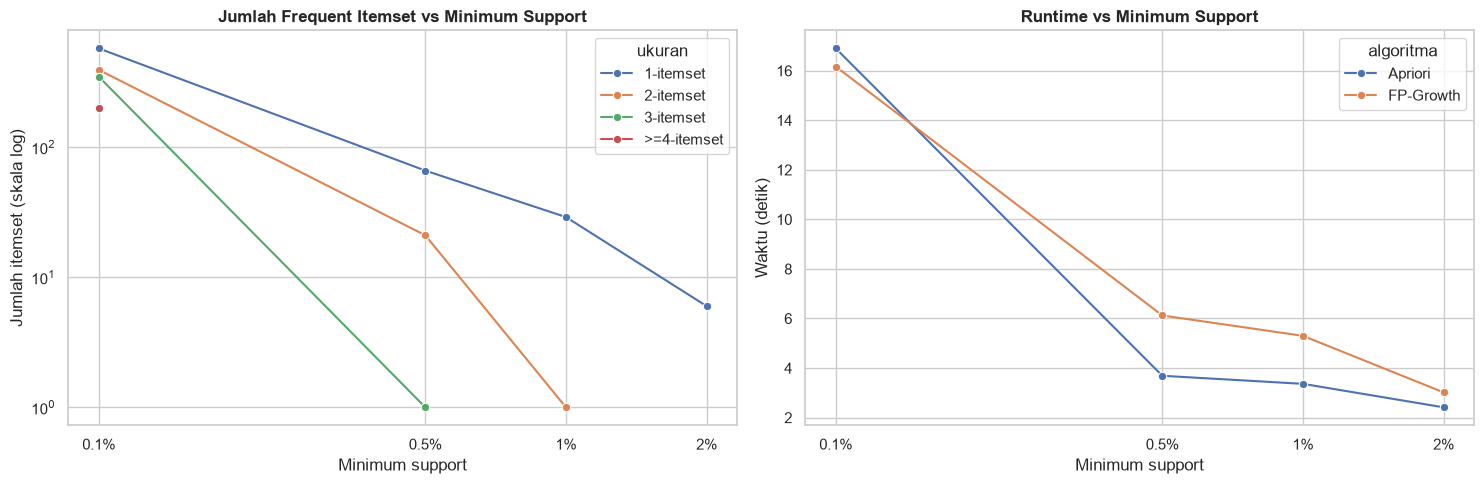

In [7]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# plot 1: pengaruh min support terhadap jumlah frequent itemset
plot_counts = summary.melt(
    id_vars="min_support",
    value_vars=["1-itemset", "2-itemset", "3-itemset", ">=4-itemset"],
    var_name="ukuran", value_name="jumlah",
)
plot_counts = plot_counts[plot_counts["jumlah"] > 0]
sns.lineplot(data=plot_counts, x="min_support", y="jumlah", hue="ukuran", marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].set_title("Jumlah Frequent Itemset vs Minimum Support", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: pengaruh min support terhadap runtime apriori vs fp-growth
rt = summary.melt(id_vars="min_support", value_vars=["apriori_s", "fpgrowth_s"], var_name="algoritma", value_name="detik")
rt["algoritma"] = rt["algoritma"].map({"apriori_s": "Apriori", "fpgrowth_s": "FP-Growth"})
sns.lineplot(data=rt, x="min_support", y="detik", hue="algoritma", marker="o", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xticks(MIN_SUPPORTS)
axes[1].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[1].set_title("Runtime vs Minimum Support", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Minimum support")
axes[1].set_ylabel("Waktu (detik)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_minsup_effect{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

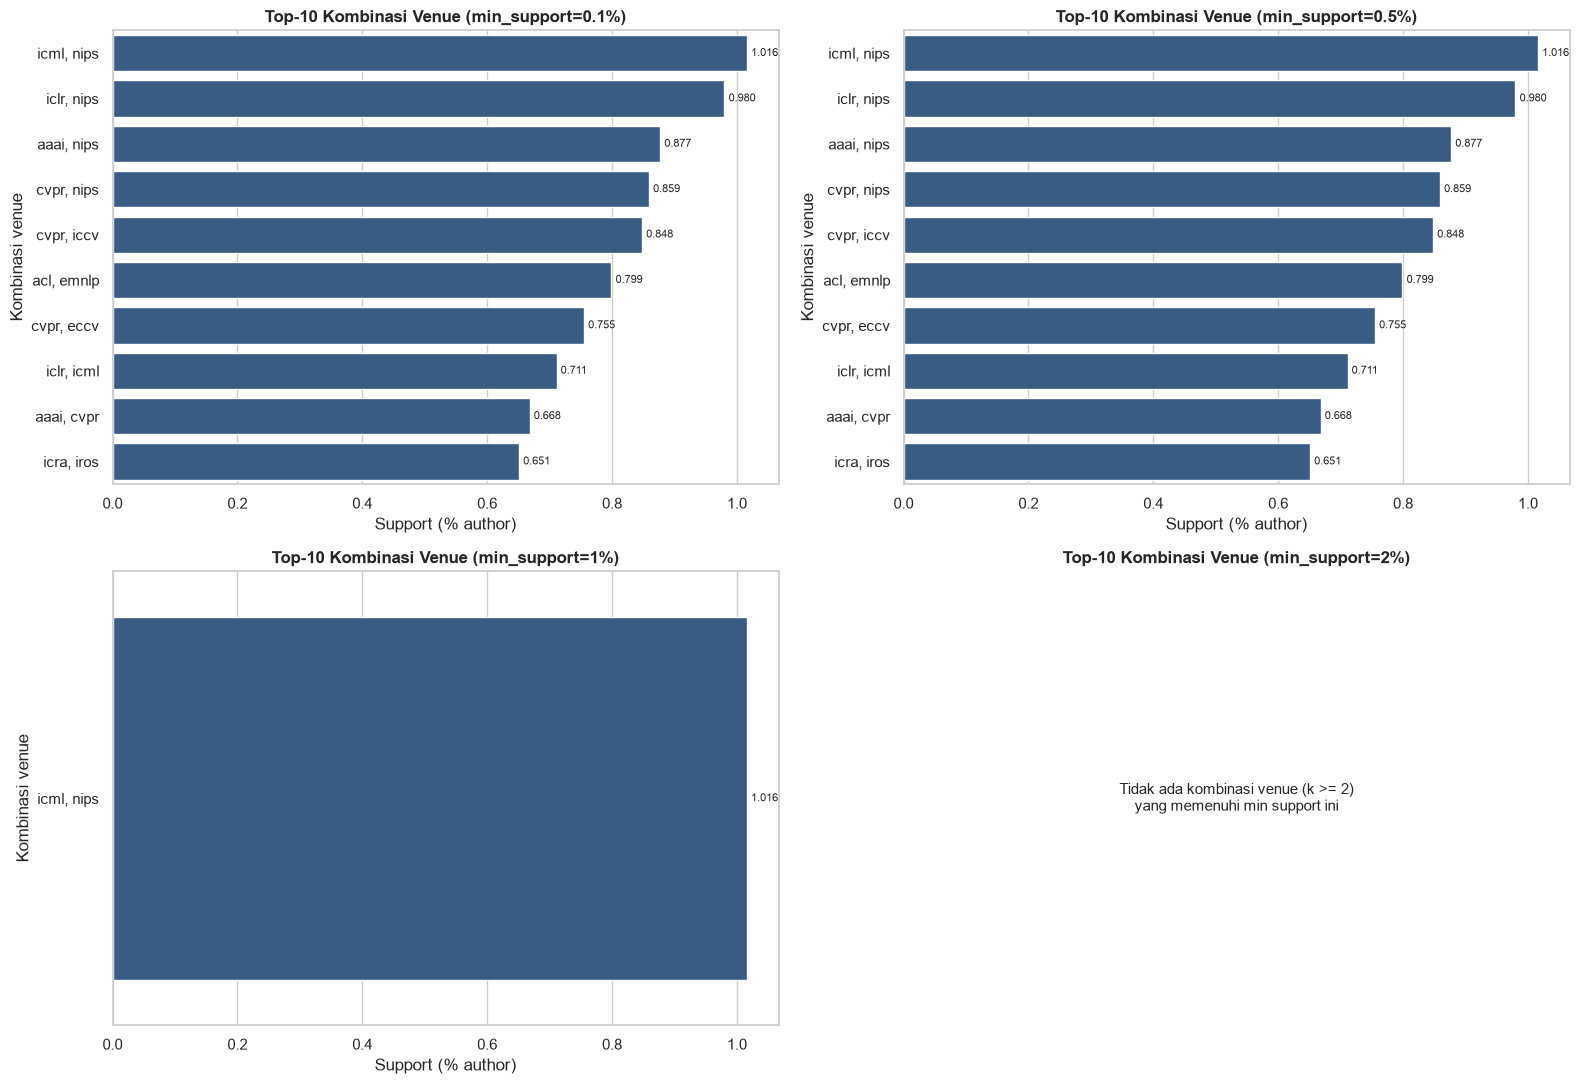

In [8]:
# plot top 10 kombinasi venue untuk setiap min support
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, ms in zip(axes.flat, MIN_SUPPORTS):
    data = top10_multi[top10_multi["min_support"] == ms]
    ax.set_title(f"Top-10 Kombinasi Venue (min_support={ms * 100:g}%)", fontsize=12, fontweight="bold")
    if len(data) == 0:
        ax.text(0.5, 0.5, "Tidak ada kombinasi venue (k >= 2)\nyang memenuhi min support ini", ha="center", va="center", fontsize=11)
        ax.set_axis_off()
        continue
    sns.barplot(data=data, y="itemset", x="support (%)", color="#2b5c8f", ax=ax)
    ax.set_xlabel("Support (% author)")
    ax.set_ylabel("Kombinasi venue")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=3)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_top10_venue_combinations{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
# bukti interpretasi (poin 6), hanya dari data tanpa label bidang venue
# 1) berapa banyak author yang publikasi di lebih dari satu venue
tx_len = pd.Series([len(t) for t in transactions])
print(f"Transaksi berisi 1 venue   : {(tx_len == 1).sum():,} ({(tx_len == 1).mean() * 100:.1f}%)")
print(f"Transaksi berisi >= 2 venue: {(tx_len >= 2).sum():,} ({(tx_len >= 2).mean() * 100:.1f}%)\n")

# 2) lift tiap pasangan frequent: lift = support(a, b) / (support(a) x support(b)), lift > 1 berarti muncul bersama lebih sering daripada kebetulan
def pair_lift_table(ms):
    res = results[ms]
    rows = []
    for itemset, count in res.items():
        if len(itemset) != 2:
            continue
        a, b = sorted(itemset)
        count_a, count_b = res[frozenset([a])], res[frozenset([b])]
        rows.append({
            "min_support": ms,
            "pasangan": f"{a}, {b}",
            "support_count": count,
            "support (%)": round(count / N * 100, 3),
            "lift": round(count * N / (count_a * count_b), 2),
        })
    return pd.DataFrame(rows, columns=["min_support", "pasangan", "support_count", "support (%)", "lift"])

pair_lift = pd.concat([pair_lift_table(ms) for ms in MIN_SUPPORTS], ignore_index=True)
pair_lift.to_csv(f"{STATS_OUT_DIR}/task4_pair_lift{SUFFIX}.csv", index=False)

for ms in MIN_SUPPORTS:
    pairs = pair_lift[pair_lift["min_support"] == ms]
    print(f"===== min_support = {ms * 100:g}% | {len(pairs):,} pasangan frequent =====")
    if len(pairs) == 0:
        print("Tidak ada pasangan frequent\n")
        continue
    print("Top-10 pasangan berdasarkan support, beserta lift-nya:")
    display(pairs.sort_values("support_count", ascending=False).head(10).reset_index(drop=True))
    print("Top-10 pasangan berdasarkan lift:")
    display(pairs.sort_values("lift", ascending=False).head(10).reset_index(drop=True))

# 3) venue populer: support venue itu sendiri, jumlah kombinasi yang memuatnya, dan lift pasangannya pada min support terendah
HUB_VENUES = ["nips", "cvpr", "aaai", "icassp", "embc", "hci", "igarss", "emnlp", "icml", "iros"]
low_pairs = pair_lift[pair_lift["min_support"] == LOWEST]
hub_rows = []
for venue in HUB_VENUES:
    row = {"venue": venue, "support venue (%)": round(results[LOWEST][frozenset([venue])] / N * 100, 3)}
    for ms in MIN_SUPPORTS:
        df_ms = itemset_dfs[ms]
        is_frequent = ((df_ms["k"] == 1) & (df_ms["itemset"] == venue)).any()
        multi = df_ms[df_ms["k"] >= 2]["itemset"].str.split(", ")
        row[f"kombinasi {ms * 100:g}%"] = int(multi.map(lambda items: venue in items).sum()) if is_frequent else None
    own = low_pairs[low_pairs["pasangan"].str.split(", ").map(lambda items: venue in items)]
    row[f"pasangan {LOWEST * 100:g}%"] = len(own)
    row[f"rata-rata lift pasangan {LOWEST * 100:g}%"] = round(own["lift"].mean(), 2) if len(own) else None
    if len(own):
        best = own.sort_values("lift", ascending=False).iloc[0]
        row["pasangan dengan lift tertinggi"] = f"{best['pasangan']} (lift {best['lift']})"
    else:
        row["pasangan dengan lift tertinggi"] = None
    hub_rows.append(row)
venue_hub = pd.DataFrame(hub_rows)
for ms in MIN_SUPPORTS:
    venue_hub[f"kombinasi {ms * 100:g}%"] = venue_hub[f"kombinasi {ms * 100:g}%"].astype("Int64")
venue_hub.to_csv(f"{STATS_OUT_DIR}/task4_venue_hub{SUFFIX}.csv", index=False)
print("Venue populer: support, jumlah kombinasi (kosong = venue tidak frequent), dan lift pasangannya:")
display(venue_hub)

# 4) kelompok venue = maximal frequent itemset: itemset frequent yang tidak menjadi bagian dari itemset frequent yang lebih besar
maximal_rows = []
for ms in MIN_SUPPORTS:
    sets = list(results[ms])
    for s in sets:
        if len(s) < 2 or any(s < t for t in sets if len(t) > len(s)):
            continue
        maximal_rows.append({"min_support": ms, "itemset": ", ".join(sorted(s)), "k": len(s),
                             "support_count": results[ms][s], "support (%)": round(results[ms][s] / N * 100, 3)})
maximal = pd.DataFrame(maximal_rows, columns=["min_support", "itemset", "k", "support_count", "support (%)"])
maximal = maximal.sort_values(["min_support", "k", "support_count"], ascending=[True, False, False]).reset_index(drop=True)
maximal.to_csv(f"{STATS_OUT_DIR}/task4_maximal_itemsets{SUFFIX}.csv", index=False)

print("Jumlah maximal frequent itemset (k >= 2) per ukuran di setiap min support:")
display(maximal.pivot_table(index="min_support", columns="k", values="itemset", aggfunc="count", fill_value=0))
for ms in MIN_SUPPORTS:
    sub = maximal[maximal["min_support"] == ms]
    if len(sub) == 0:
        print(f"min_support {ms * 100:g}%: tidak ada maximal itemset berukuran >= 2")
        continue
    print(f"min_support {ms * 100:g}%: maximal itemset terbesar (urut ukuran lalu support), maksimal 10:")
    display(sub.head(10).reset_index(drop=True))

Transaksi berisi 1 venue   : 1,063,902 (58.4%)
Transaksi berisi >= 2 venue: 757,855 (41.6%)

===== min_support = 0.1% | 393 pasangan frequent =====
Top-10 pasangan berdasarkan support, beserta lift-nya:


,min_support,pasangan,support_count,support (%),lift
0,0.001,"icml, nips",18503,1.016,18.28
1,0.001,"iclr, nips",17852,0.98,18.06
2,0.001,"aaai, nips",15973,0.877,10.84
3,0.001,"cvpr, nips",15640,0.859,10.34
4,0.001,"cvpr, iccv",15441,0.848,21.8
5,0.001,"acl, emnlp",14557,0.799,26.32
6,0.001,"cvpr, eccv",13752,0.755,22.28
7,0.001,"iclr, icml",12947,0.711,23.74
8,0.001,"aaai, cvpr",12169,0.668,10.02
9,0.001,"icra, iros",11860,0.651,24.22


Top-10 pasangan berdasarkan lift:


,min_support,pasangan,support_count,support (%),lift
0,0.001,"dac, iccad",2262,0.124,99.95
1,0.001,"sp, uss",2214,0.122,96.71
2,0.001,"ecis, icis",1822,0.1,93.71
3,0.001,"ecoc, ofc",4530,0.249,80.12
4,0.001,"ccs, sp",2336,0.128,74.96
5,0.001,"asru, interspeech",1961,0.108,74.17
6,0.001,"icse, sigsoft",2287,0.126,69.46
7,0.001,"ccs, uss",2742,0.151,69.39
8,0.001,"cicc, isscc",1881,0.103,63.96
9,0.001,"date, iccad",1872,0.103,62.26


===== min_support = 0.5% | 21 pasangan frequent =====
Top-10 pasangan berdasarkan support, beserta lift-nya:


,min_support,pasangan,support_count,support (%),lift
0,0.005,"icml, nips",18503,1.016,18.28
1,0.005,"iclr, nips",17852,0.98,18.06
2,0.005,"aaai, nips",15973,0.877,10.84
3,0.005,"cvpr, nips",15640,0.859,10.34
4,0.005,"cvpr, iccv",15441,0.848,21.8
5,0.005,"acl, emnlp",14557,0.799,26.32
6,0.005,"cvpr, eccv",13752,0.755,22.28
7,0.005,"iclr, icml",12947,0.711,23.74
8,0.005,"aaai, cvpr",12169,0.668,10.02
9,0.005,"icra, iros",11860,0.651,24.22


... (14 outputs left out)

,min_support,itemset,k,support_count,support (%)
0,0.005,"iclr, icml, nips",3,10413,0.572
1,0.005,"aaai, nips",2,15973,0.877
2,0.005,"cvpr, nips",2,15640,0.859
3,0.005,"cvpr, iccv",2,15441,0.848
4,0.005,"acl, emnlp",2,14557,0.799
5,0.005,"cvpr, eccv",2,13752,0.755
6,0.005,"aaai, cvpr",2,12169,0.668
7,0.005,"icra, iros",2,11860,0.651
8,0.005,"globecom, icc",2,11424,0.627
9,0.005,"aaai, ijcai",2,11392,0.625


min_support 1%: maximal itemset terbesar (urut ukuran lalu support), maksimal 10:


,min_support,itemset,k,support_count,support (%)
0,0.01,"icml, nips",2,18503,1.016


min_support 2%: tidak ada maximal itemset berukuran >= 2


In [10]:
from src.association_rules import generate_rules

# tambahan di luar 6 poin task 4: author-based vs author-year-based, bahan task 3 poin 5-6 dan pertanyaan kesimpulan no. 5
# load author-year db untuk dibandingkan dengan author-based
AY_TX_PATH = TX_PATH.replace("tx_author_based", "tx_author_year_based")
ay_transactions = load_transactions(AY_TX_PATH)
N_AY = len(ay_transactions)
print(f"Jumlah transaksi Author-Based      : {N:,}")
print(f"Jumlah transaksi Author-Year-Based : {N_AY:,}")

# mining author-year di min support yang sama, cukup apriori karena hasilnya sudah terbukti identik dengan fp-growth
ay_results = {ms: run_apriori(ay_transactions, ms) for ms in MIN_SUPPORTS}
ay_itemset_dfs = {ms: itemsets_to_df(res, N_AY) for ms, res in ay_results.items()}

# jumlah frequent itemset per ukuran k untuk kedua representasi
db_rows = []
for name, dfs, n_tx in [("Author-Based", itemset_dfs, N), ("Author-Year-Based", ay_itemset_dfs, N_AY)]:
    for ms, df_ms in dfs.items():
        by_k = df_ms["k"].value_counts()
        db_rows.append({
            "representasi": name,
            "min_support": ms,
            "min_support_count": math.ceil(ms * n_tx),
            "1-itemset": int(by_k.get(1, 0)),
            "2-itemset": int(by_k.get(2, 0)),
            "3-itemset": int(by_k.get(3, 0)),
            ">=4-itemset": int(by_k[by_k.index >= 4].sum()),
            "total": len(df_ms),
            "k_maks": int(df_ms["k"].max()),
        })

db_counts = pd.DataFrame(db_rows).sort_values(["min_support", "representasi"]).reset_index(drop=True)
db_counts.to_csv(f"{STATS_OUT_DIR}/task4_ab_vs_ay_counts{SUFFIX}.csv", index=False)
db_counts

Jumlah transaksi Author-Based      : 1,821,757
Jumlah transaksi Author-Year-Based : 4,085,594


,representasi,min_support,min_support_count,1-itemset,2-itemset,3-itemset,>=4-itemset,total,k_maks
0,Author-Based,0.001,1822,574,393,348,199,1514,6
1,Author-Year-Based,0.001,4086,298,46,3,0,347,3
2,Author-Based,0.005,9109,66,21,1,0,88,3
3,Author-Year-Based,0.005,20428,42,0,0,0,42,1
4,Author-Based,0.010,18218,29,1,0,0,30,2
5,Author-Year-Based,0.010,40856,17,0,0,0,17,1
6,Author-Based,0.020,36436,6,0,0,0,6,1
7,Author-Year-Based,0.020,81712,2,0,0,0,2,1


In [11]:
# top 10 kombinasi venue (k >= 2) di tiap representasi untuk setiap min support, beserta peringkat dan support di representasi lain
def ranked_multi(df_ms):
    out = df_ms.query("k >= 2").reset_index(drop=True)
    out["rank"] = out.index + 1
    return out

def top10_with_other(src, other, src_name, other_name):
    top = src.head(10)[["rank", "itemset", "support (%)"]]
    merged = top.merge(other[["itemset", "rank", "support (%)"]], on="itemset", how="left", suffixes=("", " other"))
    return merged.rename(columns={
        "rank": f"rank {src_name}",
        "support (%)": f"support {src_name} (%)",
        "rank other": f"rank {other_name}",
        "support (%) other": f"support {other_name} (%)",
    })

top10_ab_vs_ay, top10_ay_vs_ab, overlap_rows = {}, {}, []
for ms in MIN_SUPPORTS:
    ab_multi = ranked_multi(itemset_dfs[ms])
    ay_multi = ranked_multi(ay_itemset_dfs[ms])
    top10_ab_vs_ay[ms] = top10_with_other(ab_multi, ay_multi, "AB", "AY")
    top10_ay_vs_ab[ms] = top10_with_other(ay_multi, ab_multi, "AY", "AB")

    # cek apakah pola author-year juga muncul di author-based
    ab_set, ay_set = set(ab_multi["itemset"]), set(ay_multi["itemset"])
    overlap_rows.append({
        "min_support": ms,
        "kombinasi Author-Based": len(ab_set),
        "kombinasi Author-Year-Based": len(ay_set),
        "muncul di keduanya": len(ab_set & ay_set),
        "hanya di Author-Based": len(ab_set - ay_set),
        "hanya di Author-Year-Based": len(ay_set - ab_set),
    })

    print(f"===== min_support = {ms * 100:g}% =====")
    for name, table in [("Author-Based", top10_ab_vs_ay[ms]), ("Author-Year-Based", top10_ay_vs_ab[ms])]:
        if len(table) == 0:
            print(f"Top-10 kombinasi venue {name}: tidak ada\n")
        else:
            print(f"Top-10 kombinasi venue {name}:")
            display(table)

overlap = pd.DataFrame(overlap_rows)
overlap.to_csv(f"{STATS_OUT_DIR}/task4_ab_vs_ay_overlap{SUFFIX}.csv", index=False)
pd.concat([t.assign(min_support=ms) for ms, t in top10_ab_vs_ay.items()], ignore_index=True).to_csv(f"{STATS_OUT_DIR}/task4_top10_ab_vs_ay{SUFFIX}.csv", index=False)
pd.concat([t.assign(min_support=ms) for ms, t in top10_ay_vs_ab.items()], ignore_index=True).to_csv(f"{STATS_OUT_DIR}/task4_top10_ay_vs_ab{SUFFIX}.csv", index=False)

print("Irisan kombinasi venue (k >= 2) Author-Based dan Author-Year-Based di setiap min support:")
display(overlap)

===== min_support = 0.1% =====
Top-10 kombinasi venue Author-Based:


,rank AB,itemset,support AB (%),rank AY,support AY (%)
0,1,"icml, nips",1.016,1,0.434
1,2,"iclr, nips",0.980,2,0.402
2,3,"aaai, nips",0.877,6,0.301
3,4,"cvpr, nips",0.859,4,0.355
4,5,"cvpr, iccv",0.848,5,0.303
5,6,"acl, emnlp",0.799,3,0.373
6,7,"cvpr, eccv",0.755,9,0.244
7,8,"iclr, icml",0.711,7,0.272
8,9,"aaai, cvpr",0.668,10,0.244
9,10,"icra, iros",0.651,11,0.233


Top-10 kombinasi venue Author-Year-Based:


,rank AY,itemset,support AY (%),rank AB,support AB (%)
0,1,"icml, nips",0.434,1,1.016
1,2,"iclr, nips",0.402,2,0.980
2,3,"acl, emnlp",0.373,6,0.799
3,4,"cvpr, nips",0.355,4,0.859
4,5,"cvpr, iccv",0.303,5,0.848
5,6,"aaai, nips",0.301,3,0.877
6,7,"iclr, icml",0.272,8,0.711
7,8,"globecom, icc",0.272,11,0.627
8,9,"cvpr, eccv",0.244,7,0.755
9,10,"aaai, cvpr",0.244,9,0.668


===== min_support = 0.5% =====
Top-10 kombinasi venue Author-Based:


,rank AB,itemset,support AB (%),rank AY,support AY (%)
0,1,"icml, nips",1.016,NaN,NaN
1,2,"iclr, nips",0.980,NaN,NaN
2,3,"aaai, nips",0.877,NaN,NaN
3,4,"cvpr, nips",0.859,NaN,NaN
4,5,"cvpr, iccv",0.848,NaN,NaN
5,6,"acl, emnlp",0.799,NaN,NaN
6,7,"cvpr, eccv",0.755,NaN,NaN
7,8,"iclr, icml",0.711,NaN,NaN
8,9,"aaai, cvpr",0.668,NaN,NaN
9,10,"icra, iros",0.651,NaN,NaN


Top-10 kombinasi venue Author-Year-Based: tidak ada

===== min_support = 1% =====
Top-10 kombinasi venue Author-Based:


,rank AB,itemset,support AB (%),rank AY,support AY (%)
0,1,"icml, nips",1.016,NaN,NaN


Top-10 kombinasi venue Author-Year-Based: tidak ada

===== min_support = 2% =====
Top-10 kombinasi venue Author-Based: tidak ada

Top-10 kombinasi venue Author-Year-Based: tidak ada

Irisan kombinasi venue (k >= 2) Author-Based dan Author-Year-Based di setiap min support:


,min_support,kombinasi Author-Based,kombinasi Author-Year-Based,muncul di keduanya,hanya di Author-Based,hanya di Author-Year-Based
0,0.001,940,49,49,891,0
1,0.005,22,0,0,22,0
2,0.010,1,0,0,1,0
3,0.020,0,0,0,0,0


In [12]:
# association rules dari kedua representasi untuk setiap min support, min confidence 50% (sama dengan task 5)
MIN_CONFIDENCE = 0.5

def format_rules(rules: pd.DataFrame) -> pd.DataFrame:
    out = rules.copy()
    out["antecedents"] = out["antecedents"].map(lambda s: ", ".join(sorted(s)))
    out["consequents"] = out["consequents"].map(lambda s: ", ".join(sorted(s)))
    return out.round({"support": 5, "confidence": 3, "lift": 2})

ab_rules, ay_rules, rule_rows = {}, {}, []
for ms in MIN_SUPPORTS:
    ab_rules[ms] = format_rules(generate_rules(results[ms], N, MIN_CONFIDENCE))
    ay_rules[ms] = format_rules(generate_rules(ay_results[ms], N_AY, MIN_CONFIDENCE))
    rule_rows.append({
        "min_support": ms,
        "rules Author-Based": len(ab_rules[ms]),
        "rules Author-Year-Based": len(ay_rules[ms]),
        "lift maks. Author-Based": ab_rules[ms]["lift"].max() if len(ab_rules[ms]) else None,
        "lift maks. Author-Year-Based": ay_rules[ms]["lift"].max() if len(ay_rules[ms]) else None,
    })

    print(f"===== min_support = {ms * 100:g}% =====")
    print(f"Jumlah rules Author-Based      : {len(ab_rules[ms]):,}")
    print(f"Jumlah rules Author-Year-Based : {len(ay_rules[ms]):,}")
    if len(ay_rules[ms]):
        # rules author-year beserta nilai rule yang sama di author-based
        print("Rules Author-Year-Based dan nilainya di Author-Based:")
        display(ay_rules[ms].merge(ab_rules[ms], on=["antecedents", "consequents"], how="left", suffixes=(" AY", " AB")))
    if len(ab_rules[ms]):
        print("Top-10 rules Author-Based berdasarkan lift:")
        display(ab_rules[ms].head(10))
    print()

pd.concat([r.assign(min_support=ms) for ms, r in ab_rules.items()], ignore_index=True).to_csv(f"{STATS_OUT_DIR}/task4_rules_author_based{SUFFIX}.csv", index=False)
pd.concat([r.assign(min_support=ms) for ms, r in ay_rules.items()], ignore_index=True).to_csv(f"{STATS_OUT_DIR}/task4_rules_author_year{SUFFIX}.csv", index=False)

rule_counts = pd.DataFrame(rule_rows)
rule_counts.to_csv(f"{STATS_OUT_DIR}/task4_ab_vs_ay_rule_counts{SUFFIX}.csv", index=False)
print("Jumlah rules kedua representasi di setiap min support:")
display(rule_counts)

===== min_support = 0.1% =====
Jumlah rules Author-Based      : 1,387
Jumlah rules Author-Year-Based : 3
Rules Author-Year-Based dan nilainya di Author-Based:


,antecedents,consequents,support AY,confidence AY,lift AY,support AB,confidence AB,lift AB
0,"iccv, nips",cvpr,0.00101,0.561,27.12,0.00461,0.766,29.27
1,"iclr, icml",nips,0.00164,0.602,25.67,0.00572,0.804,25.35
2,"cvpr, iclr",nips,0.00104,0.555,23.70,0.00393,0.749,23.61


Top-10 rules Author-Based berdasarkan lift:


,antecedents,consequents,support,confidence,lift
0,"eccv, mm, nips","aaai, cvpr, iccv",0.00100,0.612,172.27
1,"cvpr, eccv, icml","iccv, iclr, nips",0.00101,0.502,171.81
2,"cvpr, iccv, icml, nips","eccv, iclr",0.00101,0.514,159.38
3,"cvpr, eccv, icml, nips","iccv, iclr",0.00101,0.591,157.30
4,"eccv, iccv, icml","cvpr, iclr, nips",0.00101,0.614,156.21
5,"iclr, naacl","acl, emnlp, nips",0.00105,0.504,152.46
6,"cvpr, iccv, mm, nips","aaai, eccv",0.00100,0.575,147.66
7,"emnlp, naacl, nips","acl, iclr",0.00105,0.546,146.26
8,"cvpr, eccv, mm, nips","aaai, iccv",0.00100,0.685,145.44
9,"cvpr, eccv, icml","iccv, iclr",0.00108,0.536,142.63



===== min_support = 0.5% =====
Jumlah rules Author-Based      : 7
Jumlah rules Author-Year-Based : 0
Top-10 rules Author-Based berdasarkan lift:


,antecedents,consequents,support,confidence,lift
0,"iclr, nips",icml,0.00572,0.583,33.32
1,"icml, nips",iclr,0.00572,0.563,32.91
2,"iclr, icml",nips,0.00572,0.804,25.35
3,eccv,cvpr,0.00755,0.583,22.28
4,iccv,cvpr,0.00848,0.570,21.80
5,icml,nips,0.01016,0.580,18.28
6,iclr,nips,0.00980,0.573,18.06



===== min_support = 1% =====
Jumlah rules Author-Based      : 1
Jumlah rules Author-Year-Based : 0
Top-10 rules Author-Based berdasarkan lift:


,antecedents,consequents,support,confidence,lift
0,icml,nips,0.01016,0.58,18.28



===== min_support = 2% =====
Jumlah rules Author-Based      : 0
Jumlah rules Author-Year-Based : 0

Jumlah rules kedua representasi di setiap min support:


,min_support,rules Author-Based,rules Author-Year-Based,lift maks. Author-Based,lift maks. Author-Year-Based
0,0.001,1387,3,172.27,27.12
1,0.005,7,0,33.32,NaN
2,0.010,1,0,18.28,NaN
3,0.020,0,0,NaN,NaN


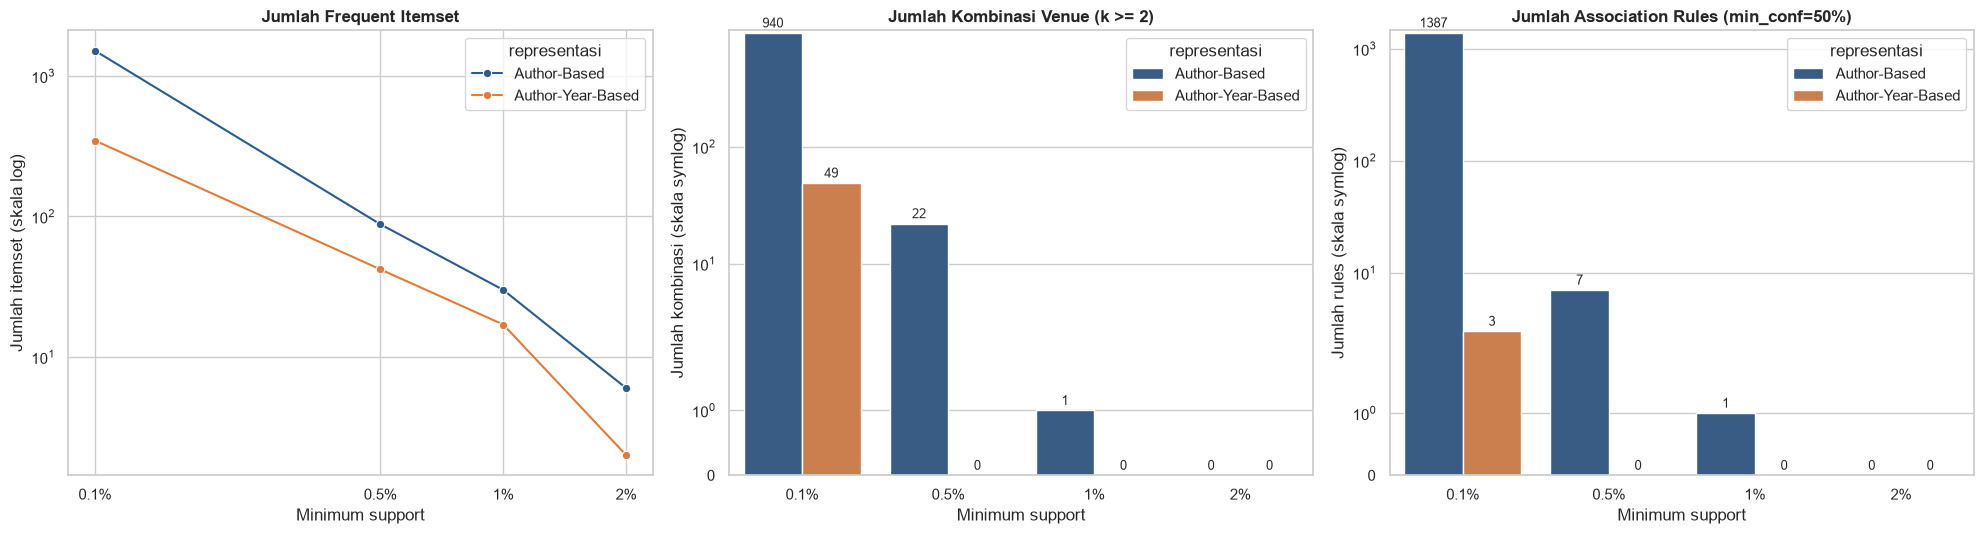

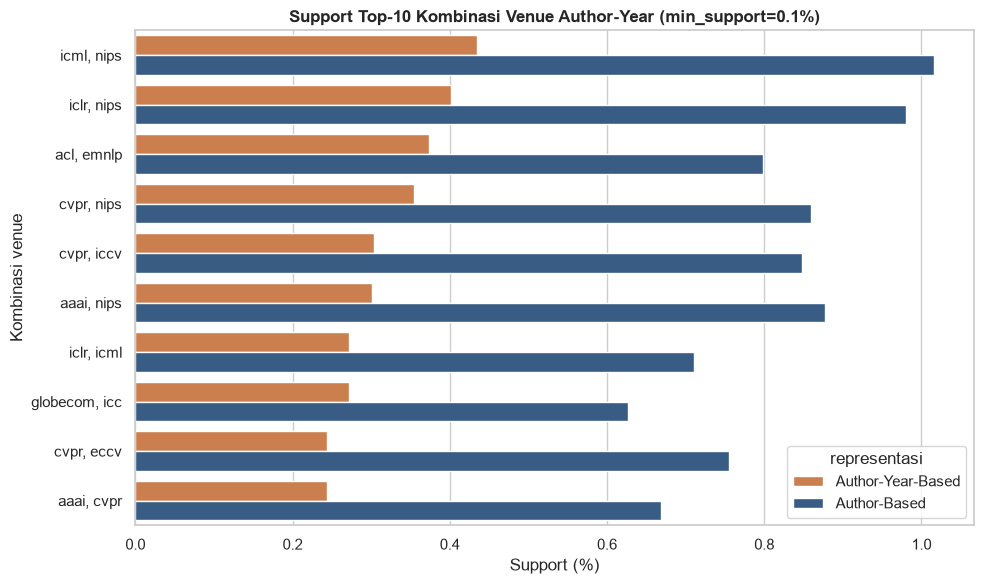

min_support 0.5%: Author-Year-Based tidak punya kombinasi venue (k >= 2), tidak ada yang diplot
min_support 1%: Author-Year-Based tidak punya kombinasi venue (k >= 2), tidak ada yang diplot
min_support 2%: Author-Year-Based tidak punya kombinasi venue (k >= 2), tidak ada yang diplot


In [13]:
palette = {"Author-Based": "#2b5c8f", "Author-Year-Based": "#e07b39"}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# plot 1: jumlah frequent itemset kedua representasi per min support
sns.lineplot(data=db_counts, x="min_support", y="total", hue="representasi", marker="o", palette=palette, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xticks(MIN_SUPPORTS)
axes[0].set_xticklabels([f"{ms * 100:g}%" for ms in MIN_SUPPORTS])
axes[0].minorticks_off()
axes[0].set_title("Jumlah Frequent Itemset", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Minimum support")
axes[0].set_ylabel("Jumlah itemset (skala log)")

# plot 2: jumlah kombinasi venue (k >= 2) per min support
combo = overlap.melt(id_vars="min_support", value_vars=["kombinasi Author-Based", "kombinasi Author-Year-Based"],
                     var_name="representasi", value_name="jumlah")
combo["representasi"] = combo["representasi"].str.replace("kombinasi ", "", regex=False)
combo["min_support"] = combo["min_support"].map(lambda ms: f"{ms * 100:g}%")
sns.barplot(data=combo, x="min_support", y="jumlah", hue="representasi", palette=palette, ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_ylim(bottom=0)
for container in axes[1].containers:
    axes[1].bar_label(container, fontsize=9, padding=2)
axes[1].set_title("Jumlah Kombinasi Venue (k >= 2)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Minimum support")
axes[1].set_ylabel("Jumlah kombinasi (skala symlog)")

# plot 3: jumlah association rules per min support
rules_long = rule_counts.melt(id_vars="min_support", value_vars=["rules Author-Based", "rules Author-Year-Based"],
                              var_name="representasi", value_name="jumlah")
rules_long["representasi"] = rules_long["representasi"].str.replace("rules ", "", regex=False)
rules_long["min_support"] = rules_long["min_support"].map(lambda ms: f"{ms * 100:g}%")
sns.barplot(data=rules_long, x="min_support", y="jumlah", hue="representasi", palette=palette, ax=axes[2])
axes[2].set_yscale("symlog")
axes[2].set_ylim(bottom=0)
for container in axes[2].containers:
    axes[2].bar_label(container, fontsize=9, padding=2)
axes[2].set_title(f"Jumlah Association Rules (min_conf={MIN_CONFIDENCE:.0%})", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Minimum support")
axes[2].set_ylabel("Jumlah rules (skala symlog)")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task4_ab_vs_ay{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

# plot support top-10 kombinasi venue author-year di kedua representasi, untuk setiap min support yang punya kombinasi
for ms in MIN_SUPPORTS:
    table = top10_ay_vs_ab[ms]
    if len(table) == 0:
        print(f"min_support {ms * 100:g}%: Author-Year-Based tidak punya kombinasi venue (k >= 2), tidak ada yang diplot")
        continue
    plot_top = table.melt(id_vars="itemset", value_vars=["support AY (%)", "support AB (%)"],
                          var_name="representasi", value_name="support (%)")
    plot_top["representasi"] = plot_top["representasi"].map({"support AY (%)": "Author-Year-Based", "support AB (%)": "Author-Based"})
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=plot_top, y="itemset", x="support (%)", hue="representasi", palette=palette, ax=ax)
    ax.set_title(f"Support Top-10 Kombinasi Venue Author-Year (min_support={ms * 100:g}%)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Support (%)")
    ax.set_ylabel("Kombinasi venue")
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/task4_ay_top10_support_minsup_{ms}{SUFFIX}.png", dpi=300, bbox_inches="tight")
    plt.show()